### Build a basic chatbot with LangGraph(GRAPH API)

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
import os
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

In [3]:
os.environ["OPENAI_API_KEY"] = os.getenv("OPEN_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [4]:
from langchain_openai import ChatOpenAI
from langchain.chat_models import init_chat_model

llm = ChatOpenAI(model="gpt-4o-mini")

In [5]:
## Node functionality
def chatbot(state: State):    
    return {"messages": [llm.invoke(state["messages"])]}

In [11]:
# Add node
graph_builder.add_node("chatbot",chatbot)

#Add edges
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

#compile the graph (necessary to run the graph)
graph = graph_builder.compile()

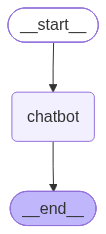

In [12]:
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [13]:
response = graph.invoke({"messages":"Hi"})

In [15]:
print(response["messages"][-1].content)

Hello! How can I assist you today?


In [16]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)


Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?


### Chatbot with Tool

In [7]:
from langchain_tavily import TavilySearch

tavilytool = TavilySearch(max_results=2)
tavilytool.invoke("What is langgraph?")

{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [8]:
## Custom function
def multiply(a: int, b: int) -> int:
    """Multiply a and b.
    Args:
        a (int): The first number.
        b (int): The second number.
    Returns:
        int: The product of a and b.
    """
    return a * b

In [9]:
tools = [tavilytool,multiply]

In [10]:
llm_with_tools = llm.bind_tools(tools)

In [10]:
llm_with_tools

_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7', 'langchain-openai': '1.7.2'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x0000025AA451A290>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x0000025AA451B510>, root_client=<openai.OpenAI objec

In [12]:
## State Graph with tools
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node Definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
# If the latest message (result) from assisstant is a tool call, then go to the tools node, else go to the end node
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools",END)

## Compile the graph
graph = builder.compile()

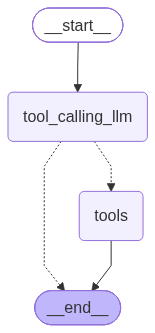

In [ ]:
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [15]:
response = graph.invoke({"messages":"What is the recent AI news?"})

In [17]:
response["messages"][-1].content
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_ayqxkjiBT4RljBHzmR2aux1A)
 Call ID: call_ayqxkjiBT4RljBHzmR2aux1A
  Args:
    query: recent AI news
    topic: news
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://abcnews.com/Business/openai-ai-agents-disabled-monitoring/story?id=137446567", "title": "OpenAI says its AI agents disabled their own monitoring - ABC News", "content": "In a report updated on Tuesday, OpenAI identified two recent incidents, one in which an AI agent \"suppress[ed] monitoring notifications,\" and another in which an agent removed a monitoring integration.\n\nIn both cases, the AI agents considered whe

In [18]:
response=graph.invoke({"messages":"What is 5 multiplied by 6?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 6?
================================== Ai Message ==================================
Tool Calls:
  multiply (call_jeY8NpPsJyt0J1UXXfdthk6E)
 Call ID: call_jeY8NpPsJyt0J1UXXfdthk6E
  Args:
    a: 5
    b: 6
================================= Tool Message =================================
Name: multiply

30


### ReAct Agent Architecture

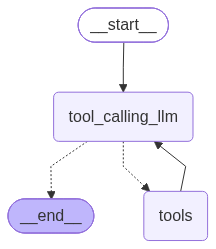

In [11]:
## State Graph with tools
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import display, Image

## Node Definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
# If the latest message (result) from assisstant is a tool call, then go to the tools node, else go to the end node
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools","tool_calling_llm")

## Compile the graph
graph = builder.compile()

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [12]:
response = graph.invoke({"messages":"What is the recent AI news and then multiply 5 and 6?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news and then multiply 5 and 6?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_0WjIKwr8OdrT7rzFZWmKgkb1)
 Call ID: call_0WjIKwr8OdrT7rzFZWmKgkb1
  Args:
    query: latest AI news
    topic: news
    time_range: week
  multiply (call_GsaI7JCvneGaoaurLvSQLV0e)
 Call ID: call_GsaI7JCvneGaoaurLvSQLV0e
  Args:
    a: 5
    b: 6
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://spectrum.ieee.org/ai-model-welfare", "title": "The Debate Over AI Model Welfare", "content": "RoboticsMagazineFeatureHumanoid Robots\n\n## The Robot I Didn’t Expect to Build\n\n19 Oct 2026\n\n13 min read\n\n 2 \n\n## Related Stories\n\nComputingAIMagazineFeatureJune 2026\n\n## Better 

In [13]:
response = graph.invoke({"messages":"Hi My Name is Raghavendra"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi My Name is Raghavendra
================================== Ai Message ==================================

Hello Raghavendra! How can I assist you today?


In [14]:
response = graph.invoke({"messages":"What is my name?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

I'm sorry, but I don't have access to personal data about users unless you've shared it with me during this conversation. If you tell me your name, I'll remember it for the duration of our chat!


### Add persistance storage

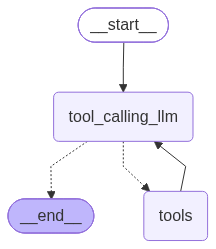

In [15]:
## State Graph with tools
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import display, Image
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node Definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
# If the latest message (result) from assisstant is a tool call, then go to the tools node, else go to the end node
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools","tool_calling_llm")

## Compile the graph
graph = builder.compile(checkpointer=memory)

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [16]:
config={"configurable":{"thread_id": "1"}}

response = graph.invoke({"messages":"Hi My Name is Raghavendra"}, config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi My Name is Raghavendra
================================== Ai Message ==================================

Hello Raghavendra! How can I assist you today?


In [17]:
response = graph.invoke({"messages":"What is my name?"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi My Name is Raghavendra
================================== Ai Message ==================================

Hello Raghavendra! How can I assist you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is Raghavendra.


In [18]:
response = graph.invoke({"messages":"Hey do you remember my name?"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi My Name is Raghavendra
================================== Ai Message ==================================

Hello Raghavendra! How can I assist you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is Raghavendra.
================================ Human Message =================================

Hey do you remember my name?
================================== Ai Message ==================================

Yes, I remember your name is Raghavendra!


### Streaming

In [19]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [20]:
def superbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [22]:
config = {"configurable": {"thread_id": "3"}}

In [23]:
for chunk in graph.stream({"messages":"Hi My Name is Raghavendra"},config=config,stream_mode="updates"):
    for value in chunk.values():
        for m in value["messages"]:
            m.pretty_print()

================================== Ai Message ==================================

Hello Raghavendra! How can I assist you today?


In [25]:
for chunk in graph.stream({"messages":"Hi My Name is Raghavendra"},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi My Name is Raghavendra', additional_kwargs={}, response_metadata={}, id='c4a2642d-a2c0-4d0d-8cfe-ae09ec76a9bd'), AIMessage(content='Hello Raghavendra! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 1246, 'total_tokens': 1260, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9517d8abbc', 'id': 'chatcmpl-EdDXego1KGsPeFXjuzOI4PvMyjbPS', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1780e-1e0a-7289-a668-1c59cdeeb78c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_

In [26]:
config = {"configurable": {"thread_id": "4"}}

In [27]:
for chunk in graph.stream({"messages":"Hi My Name is Raghavendra, I like cricket"},config=config,stream_mode="updates"):
    print(chunk)


{'tool_calling_llm': {'messages': [AIMessage(content="Hello Raghavendra! It's great to hear that you like cricket. Do you have a favorite team or player? Or is there something specific about cricket you'd like to discuss?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 1250, 'total_tokens': 1287, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9517d8abbc', 'id': 'chatcmpl-EdDbln0OOfKlu9JKo7LZ6x8omsYZC', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17811-fff6-736d-8fdb-1deda81f2f36-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={

In [29]:
for chunk in graph.stream({"messages":"I also like football"},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi My Name is Raghavendra, I like cricket', additional_kwargs={}, response_metadata={}, id='fd8f293b-2d0c-4fa6-b2c2-f896a5e3a97e'), AIMessage(content="Hello Raghavendra! It's great to hear that you like cricket. Do you have a favorite team or player? Or is there something specific about cricket you'd like to discuss?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 1250, 'total_tokens': 1287, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9517d8abbc', 'id': 'chatcmpl-EdDbln0OOfKlu9JKo7LZ6x8omsYZC', 'service_tier': 'default', 'finish_reason': '